# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

## Best ML runs

In [2]:
runs_to_download = []

runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'HybridModel'", experiment_ids=['6'], output_format='list'))
runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'MLP'", experiment_ids=['6'], output_format='list'))
print(len(runs_to_download))


20


In [3]:
import os

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [4]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-09-21 11:28:49,505 - INFO - Downloading artifacts for run 1398da59c8114ed7a5d6e7645ec53c15
2026-09-21 11:28:51,970 - INFO - Downloading artifacts for run ed029d2fe66d464b87d0de88702a288b


2026-09-21 11:28:54,294 - INFO - Downloading artifacts for run 767f7d4abfc24cb5bc70c16605a7cda1
2026-09-21 11:28:57,067 - INFO - Downloading artifacts for run 2a167d82d9b7466b9bcc516348e0d1bb
2026-09-21 11:28:59,747 - INFO - Downloading artifacts for run 4b1770399d674e66856c1f5ee46ac39b
2026-09-21 11:29:02,306 - INFO - Downloading artifacts for run 6374036bf8c14d06b3f14514e55608ed
2026-09-21 11:29:04,803 - INFO - Downloading artifacts for run 7812fd2a258847b0944da51aa43e4425
2026-09-21 11:29:07,411 - INFO - Downloading artifacts for run 6e073a4ba06b43868e694f3f814ae801
2026-09-21 11:29:09,949 - INFO - Downloading artifacts for run 9e60290ab8f84fda80679e1d6611e208
2026-09-21 11:29:12,429 - INFO - Downloading artifacts for run fe14623abec64c148ba388ddd251ac63
2026-09-21 11:29:15,050 - INFO - Downloading artifacts for run 4ce2c0cbe5454315b45fb0277d11fd12
2026-09-21 11:29:17,285 - INFO - Downloading artifacts for run 1cd5efb3ef374f51ad9a5ced5e80d541
2026-09-21 11:29:19,520 - INFO - Downloa

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.794304,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
1,Node_1,0.0,0.634236,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
2,Node_2,0.0,0.580157,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
3,Node_3,0.0,0.791183,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc
4,Node_4,0.0,0.930520,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc


In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
model_name_df

,run_id,model_name,modelled_genes
0,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
1,ed029d2fe66d464b87d0de88702a288b,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N..."
2,767f7d4abfc24cb5bc70c16605a7cda1,HybridModel,"['Node_78', 'Node_22', 'Node_26', 'Node_73', '..."
3,2a167d82d9b7466b9bcc516348e0d1bb,HybridModel,"['Node_37', 'Node_12', 'Node_17', 'Node_25', '..."
4,4b1770399d674e66856c1f5ee46ac39b,HybridModel,"['Node_32', 'Node_10', 'Node_39', 'Node_92', '..."
5,6374036bf8c14d06b3f14514e55608ed,HybridModel,"['Node_28', 'Node_4', 'Node_13', 'Node_29', 'N..."
6,7812fd2a258847b0944da51aa43e4425,HybridModel,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N..."
7,6e073a4ba06b43868e694f3f814ae801,HybridModel,"['Node_63', 'Node_0', 'Node_24', 'Node_19', 'N..."
8,9e60290ab8f84fda80679e1d6611e208,HybridModel,"['Node_31', 'Node_20', 'Node_27', 'Node_34', '..."
9,fe14623abec64c148ba388ddd251ac63,HybridModel,"['Node_36', 'Node_14', 'Node_51', 'Node_40', '..."


In [6]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')

Add number of genes

In [7]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    run = mlflow.get_run(run_id)
    records.append({
        'parent_run_id': run_id,
        'nr_genes': run.data.params['nr_genes'],
    })
nr_genes_df = pd.DataFrame(records)
nr_genes_df.head()

,parent_run_id,nr_genes
0,f862625665764f1383bf88e5615594dc,100
1,f02bf732b2ba4817b254bd5174f1549b,50
2,6a8078c2c7764850b1fb8b3c33553a1b,20


Add noiseless expression values

In [8]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-09-21 11:29:49,023 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,174 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,237 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,389 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,474 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,573 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,656 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:49,753 - WARNING - Connection p

2026-09-21 11:29:55,272 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,351 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,430 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,530 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,642 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,816 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:55,883 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-09-21 11:29:56,008 - WARNING - Connection p

In [9]:
nr_genes_df.head()

,parent_run_id,nr_genes
0,f862625665764f1383bf88e5615594dc,100
1,f02bf732b2ba4817b254bd5174f1549b,50
2,6a8078c2c7764850b1fb8b3c33553a1b,20


In [10]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.794304,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
1,Node_1,0.0,0.634236,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
2,Node_2,0.0,0.580157,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
3,Node_3,0.0,0.791183,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."
4,Node_4,0.0,0.930520,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,f862625665764f1383bf88e5615594dc,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod..."


In [11]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.825063,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
1,Node_1,0.0,0.666242,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
2,Node_2,0.0,0.291667,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
3,Node_3,0.0,0.830106,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc
4,Node_4,0.0,0.940870,KO: Node_0. Env: None,f862625665764f1383bf88e5615594dc


Merging

In [12]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])

outcome = pd.merge(outcome, nr_genes_df, on='parent_run_id')

In [13]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'nr_genes']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,nr_genes
0,Node_0,0.0,0.794304,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.825063,100
1,Node_1,0.0,0.634236,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.666242,100
2,Node_2,0.0,0.580157,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.291667,100
3,Node_3,0.0,0.791183,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.830106,100
4,Node_4,0.0,0.930520,KO: Node_15. Env: None,1398da59c8114ed7a5d6e7645ec53c15,HybridModel,"['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Nod...",0.940870,100
...,...,...,...,...,...,...,...,...,...
5300395,Node_15,1.0,0.150534,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.095201,20
5300396,Node_16,1.0,0.662094,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.786299,20
5300397,Node_17,1.0,0.205379,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.106327,20
5300398,Node_18,1.0,0.583916,KO: Node_14. Env: None,8db98dfd72b643e4b5536eeb07f3cadc,MLP,None,0.547510,20


In [14]:
outcome['model_name'].unique()

array(['HybridModel', 'MLP'], dtype=object)

In [15]:
outcome['model_name_long'] = outcome['model_name'] + outcome['modelled_genes'].str[:20].fillna('')

In [16]:
outcome['model_name_long'].nunique()

18

In [17]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [18]:
stdev_df = outcome.groupby(['gene', 'condition', 'nr_genes'])['noiseless_ground_truth'].std().reset_index().rename(
    columns={'noiseless_ground_truth': 'gene_expression_stdev'})
stdev_df.head()

,gene,condition,nr_genes,gene_expression_stdev
0,Node_0,"KO: Node_0, Node_1. Env: None",20,0.194000
1,Node_0,"KO: Node_0, Node_13. Env: None",20,0.197007
2,Node_0,"KO: Node_0, Node_13. Env: None",50,0.023130
3,Node_0,"KO: Node_0, Node_19. Env: None",100,0.137513
4,Node_0,"KO: Node_0, Node_19. Env: None",50,0.022173


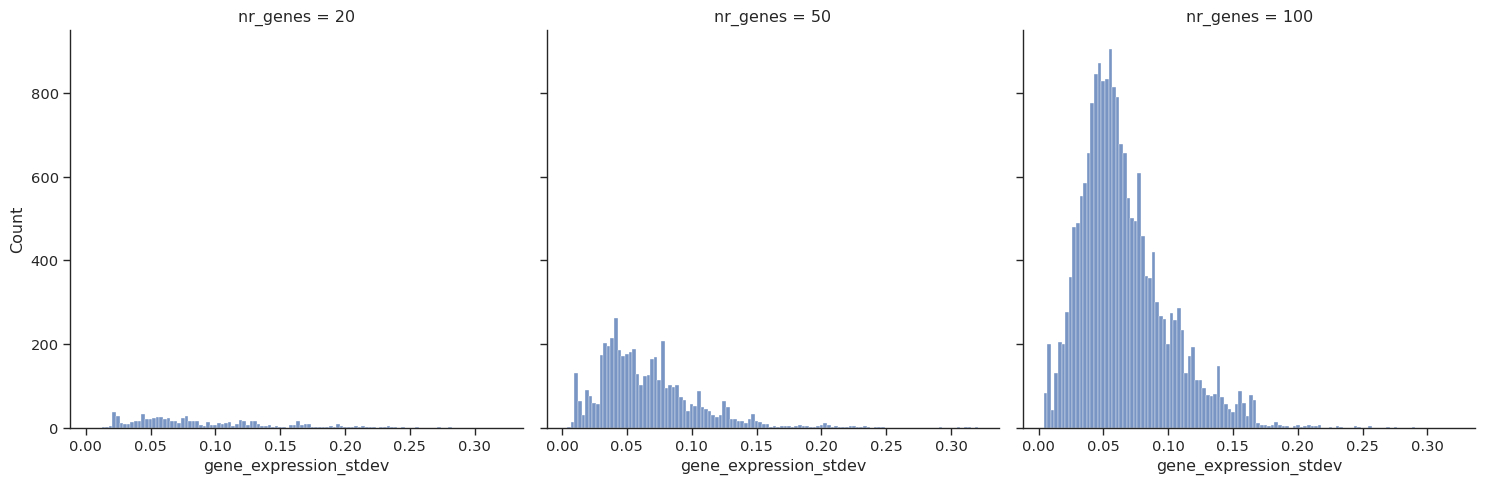

In [68]:
sns.displot(data =stdev_df, col='nr_genes', x='gene_expression_stdev')

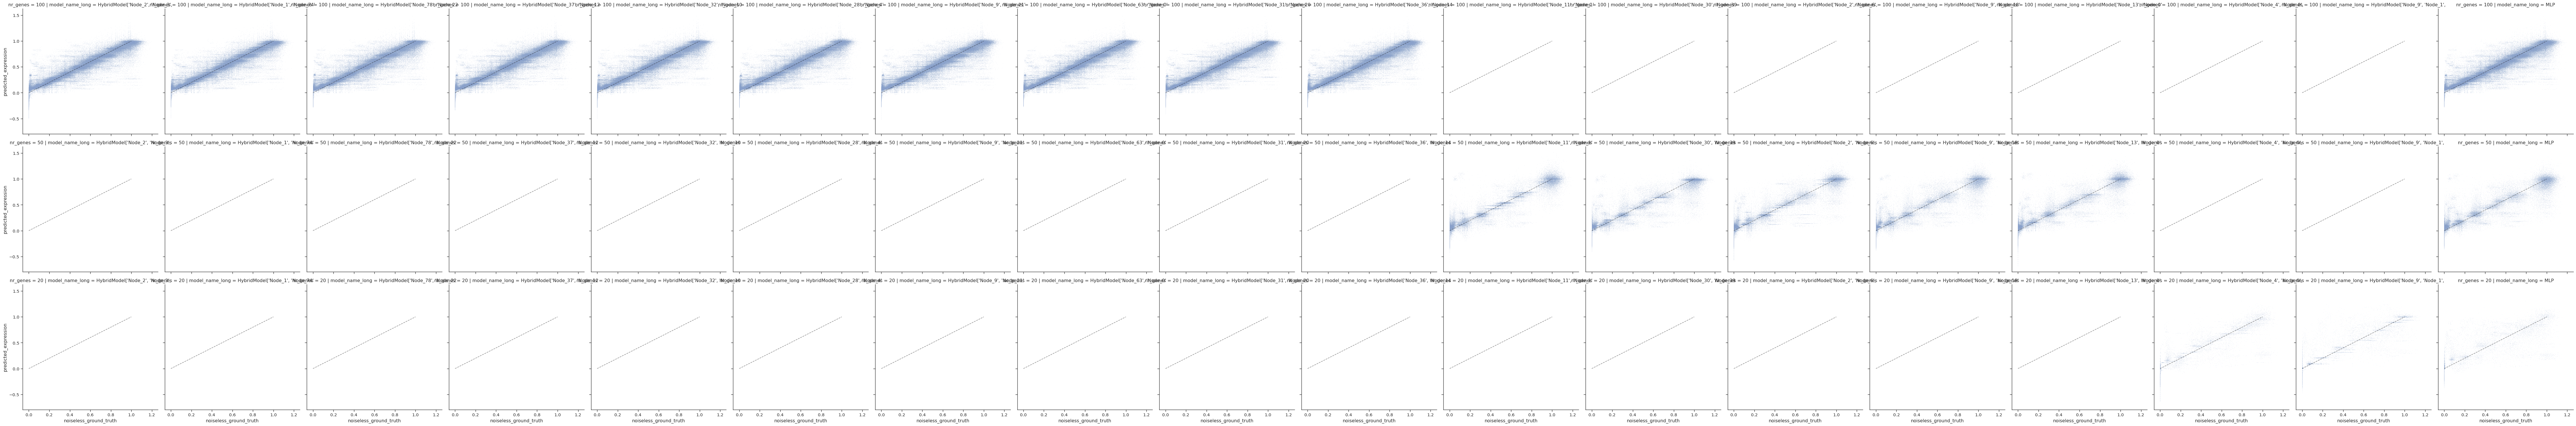

In [69]:
g = sns.relplot(data=double_ko_df, kind='scatter', x='noiseless_ground_truth', y='predicted_expression', col='model_name_long', row='nr_genes', s=2, alpha=.2, marker='.')

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

# Plotting for double KO

In [19]:
from copy import deepcopy
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [20]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
    'nr_genes'
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'nr_genes', 'MSE']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'nr_genes', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition', 'nr_genes'])
paired = annotate_kos_in_df(paired)


In [21]:
paired.head()

,gene,condition,nr_genes,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm
0,Node_0,"KO: Node_0, Node_19. Env: None",100,0.030686,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029936,none,False
1,Node_0,"KO: Node_0, Node_2. Env: None",100,0.031205,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029662,none,False
2,Node_0,"KO: Node_0, Node_23. Env: None",100,0.023840,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.023259,none,False
3,Node_0,"KO: Node_0, Node_24. Env: None",100,0.022217,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.021572,none,False
4,Node_0,"KO: Node_0, Node_3. Env: None",100,0.026834,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.025545,none,False


In [22]:
mse_df.head()

,model_name,modelled_genes,gene,condition,nr_genes,MSE
0,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",Node_0,"KO: Node_0, Node_19. Env: None",100,0.030686
1,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",Node_0,"KO: Node_0, Node_2. Env: None",100,0.031205
2,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",Node_0,"KO: Node_0, Node_23. Env: None",100,0.023840
3,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",Node_0,"KO: Node_0, Node_24. Env: None",100,0.022217
4,HybridModel,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",Node_0,"KO: Node_0, Node_3. Env: None",100,0.026834


In [23]:
paired.modelled_genes.value_counts()

modelled_genes
['Node_1', 'Node_74', 'Node_42', 'Node_15', 'Node_8', 'Node_16', 'Node_11', 'Node_46', 'Node_38', 'Node_44', 'Node_60', 'Node_70', 'Node_82', 'Node_71']    10000
['Node_2', 'Node_3', 'Node_6', 'Node_23', 'Node_7', 'Node_43', 'Node_55', 'Node_61', 'Node_52', 'Node_76', 'Node_79', 'Node_83', 'Node_89']                 10000
['Node_32', 'Node_10', 'Node_39', 'Node_92', 'Node_85', 'Node_30', 'Node_47', 'Node_66', 'Node_94', 'Node_99']                                              10000
['Node_31', 'Node_20', 'Node_27', 'Node_34', 'Node_50', 'Node_64', 'Node_75', 'Node_72', 'Node_62']                                                         10000
['Node_28', 'Node_4', 'Node_13', 'Node_29', 'Node_56', 'Node_59', 'Node_67', 'Node_95', 'Node_97', 'Node_98']                                               10000
['Node_78', 'Node_22', 'Node_26', 'Node_73', 'Node_49', 'Node_48', 'Node_33', 'Node_80', 'Node_93']                                                         10000
['Node_63', '

/tmp/ipykernel_2863218/3707286802.py:5: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',


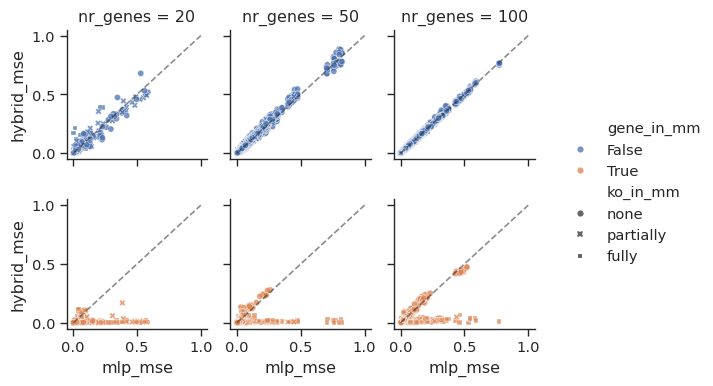

In [24]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',
                  alpha=.75, s=20, col_order=natsorted(paired['nr_genes'].unique()), height=2, aspect=1,
                    facet_kws={'margin_titles': True}, palette=palette)
# g.figure.set_size_inches(9, 3) 
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
for text in g._margin_titles_texts:
    text.set_visible(False)
# g.savefig("scatter_mlp_hybrid_lin_no_hue.pdf", dpi=600, bbox_inches='tight', )

Count points above ref line for ko outside but gene inside MM, dataset 50 genes

In [25]:
selected_rows = paired[(paired['ko_in_mm'] == 'none') & (paired['gene_in_mm'] == True) & (paired['nr_genes'] == '50')]
selected_rows.shape


(1873, 8)

In [26]:
selected_rows.head()

,gene,condition,nr_genes,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm
10050,Node_1,"KO: Node_0, Node_13. Env: None",50,0.005287,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.006343,none,True
10051,Node_1,"KO: Node_0, Node_19. Env: None",50,0.003426,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.023879,none,True
10052,Node_1,"KO: Node_0, Node_24. Env: None",50,0.002813,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.019702,none,True
10053,Node_1,"KO: Node_0, Node_28. Env: None",50,0.006766,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.028476,none,True
10054,Node_1,"KO: Node_0, Node_29. Env: None",50,0.002641,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.005275,none,True


In [31]:
selected_rows['mlp_mse'].mean()

np.float64(0.014531636174469278)

In [30]:
selected_rows['hybrid_mse'].mean()

np.float64(0.006737627960344452)

In [29]:
(selected_rows['hybrid_mse'] > selected_rows['mlp_mse']).value_counts()

False    1544
True      329
Name: count, dtype: int64

In [28]:
329/1873

0.17565403096636412

2026-07-06 14:23:04,774 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-06 14:23:04,786 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-07-06 14:23:04,805 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


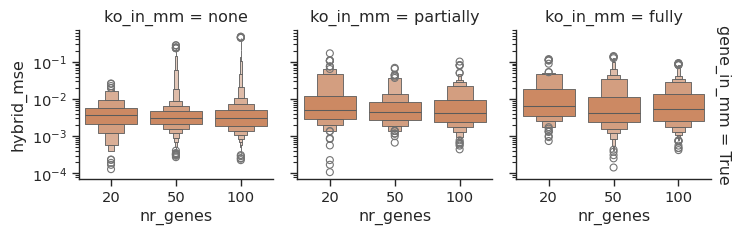

In [76]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g= sns.catplot(data=paired[paired['gene_in_mm'] == True], kind='boxen',x='nr_genes', y='hybrid_mse',  height=2.5, aspect=1,
            log_scale=True, order=natsorted(paired['nr_genes'].unique()), col='ko_in_mm', row='gene_in_mm', color=sns.color_palette()[1],
            margin_titles= True)

# g.savefig("hybrid_mse_gene_in_mm_but_ko_in_or_out.pdf", dpi=600, bbox_inches='tight')

In [77]:
paired_with_variation_per_gene = pd.merge(paired, stdev_df, 'left', on=['gene', 'condition', 'nr_genes'])
paired_with_variation_per_gene.shape

(113300, 9)

In [78]:
epistasis_df = pd.read_csv('epistasis_levels.csv')
epistasis_df['nr_genes'] = epistasis_df['nr_genes'].astype(str)

In [79]:
paired

,gene,condition,nr_genes,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm
0,Node_0,"KO: Node_0, Node_19. Env: None",100,0.030686,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029936,none,False
1,Node_0,"KO: Node_0, Node_2. Env: None",100,0.031205,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029662,none,False
2,Node_0,"KO: Node_0, Node_23. Env: None",100,0.023840,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.023259,none,False
3,Node_0,"KO: Node_0, Node_24. Env: None",100,0.022217,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.021572,none,False
4,Node_0,"KO: Node_0, Node_3. Env: None",100,0.026834,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.025545,none,False
...,...,...,...,...,...,...,...,...
113295,Node_99,"KO: Node_8, Node_9. Env: None",100,0.001715,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.001480,partially,False
113296,Node_99,"KO: Node_9, Node_21. Env: None",100,0.002034,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.001695,fully,False
113297,Node_99,"KO: Node_9, Node_26. Env: None",100,0.002582,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.002310,partially,False
113298,Node_99,"KO: Node_9, Node_41. Env: None",100,0.002741,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.002785,fully,False


In [80]:
paired = pd.merge(paired, epistasis_df[['condition', 'gene', 'single-to-double-ko-divergence', 'nr_genes']])
paired

,gene,condition,nr_genes,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm,single-to-double-ko-divergence
0,Node_0,"KO: Node_0, Node_19. Env: None",100,0.030686,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029936,none,False,0.049926
1,Node_0,"KO: Node_0, Node_2. Env: None",100,0.031205,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.029662,none,False,0.051992
2,Node_0,"KO: Node_0, Node_23. Env: None",100,0.023840,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.023259,none,False,0.049973
3,Node_0,"KO: Node_0, Node_24. Env: None",100,0.022217,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.021572,none,False,0.051128
4,Node_0,"KO: Node_0, Node_3. Env: None",100,0.026834,"['Node_1', 'Node_74', 'Node_42', 'Node_15', 'N...",0.025545,none,False,0.050190
...,...,...,...,...,...,...,...,...,...
113295,Node_99,"KO: Node_8, Node_9. Env: None",100,0.001715,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.001480,partially,False,0.110346
113296,Node_99,"KO: Node_9, Node_21. Env: None",100,0.002034,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.001695,fully,False,0.109761
113297,Node_99,"KO: Node_9, Node_26. Env: None",100,0.002582,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.002310,partially,False,0.115904
113298,Node_99,"KO: Node_9, Node_41. Env: None",100,0.002741,"['Node_9', 'Node_21', 'Node_41', 'Node_54', 'N...",0.002785,fully,False,0.107971


In [89]:
def get_row_label(row):
    if row['gene_in_mm']:
        return f"gene in MM,KO in mm = {row['ko_in_mm']}"
    else:
        return 'gene not in MM'

In [90]:
paired['row_label'] = paired.apply(get_row_label, axis=1)

In [83]:
round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)

np.float64(0.2)

/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/lustre/BIF/nobackup/noord087/miniforge3/envs/halcyon/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


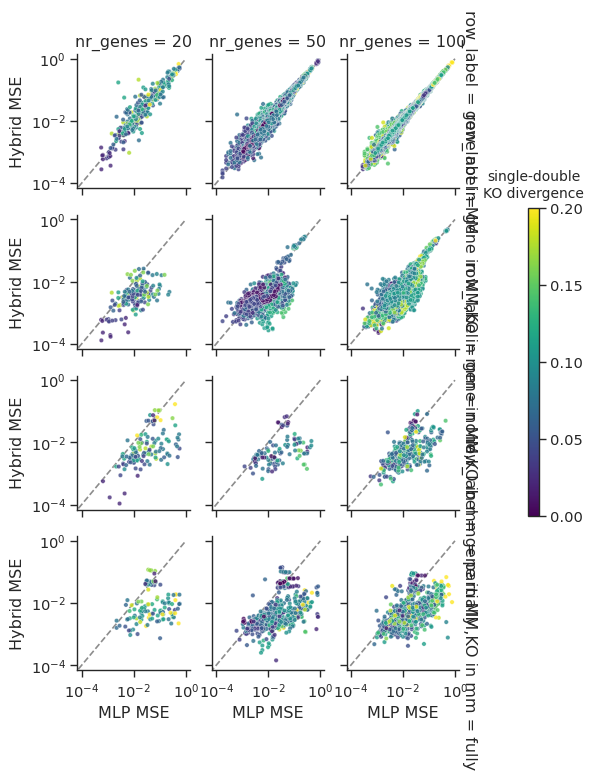

In [ ]:
import textwrap 

sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()

cmap = 'viridis'
# min_scale = paired['single-to-double-ko-divergence'].min()
# max_scale = paired['single-to-double-ko-divergence'].max()

min_scale = round(paired['single-to-double-ko-divergence'].quantile(0.01), 1)
max_scale = round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)

norm = Normalize(min_scale, max_scale)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='nr_genes',
                 row='row_label', hue='single-to-double-ko-divergence', legend=False,
                  alpha=.8, s=10, col_order=natsorted(paired['nr_genes'].unique()),
                    height=2, aspect=1, palette=cmap, hue_norm=norm,
                      facet_kws={'margin_titles': True})

g.set(xscale='log', yscale='log')
# g.set_titles(row_template="{row_name}", col_template="nr_genes = {col_name}")
cbar = g.figure.colorbar(sm, 
                        ax=g.axes, 
                        shrink=0.5,       # scales the bar's length (0 to 1)
                        aspect=30,        # higher = thinner bar (default is ~20)
                        fraction=0.03,    # how much of the figure width it eats up
                        pad=0.15,         # gap between the bar and the last facet
                        )

wrapped_title = textwrap.fill('single-double KO divergence', width=15)

cbar.ax.set_title(wrapped_title, fontsize=10, pad=8)
cbar.set_ticks(np.arange(min_scale, max_scale+0.05, 0.05))

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
ticks = [1e-4, 1e-2, 1e0]
g.set_axis_labels('MLP MSE', 'Hybrid MSE')

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    # ax.plot([global_min, global_max], [global_min, global_max], 'k--', lw=0.8, zorder=0)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)

g.savefig("scatter_mlp_hybrid_log_hue_ko_divergence.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
import textwrap 

sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()

cmap = 'viridis'
# min_scale = paired['single-to-double-ko-divergence'].min()
# max_scale = paired['single-to-double-ko-divergence'].max()

min_scale = round(paired['single-to-double-ko-divergence'].quantile(0.01), 1)
max_scale = round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)

norm = Normalize(min_scale, max_scale)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

g = sns.relplot(data=paired[paired['gene_in_mm']== True], x='mlp_mse', y='hybrid_mse', col='nr_genes', row='ko_in_mm', hue='single-to-double-ko-divergence', legend=False,
                  alpha=.8, s=10, col_order=natsorted(paired['nr_genes'].unique()), height=2, aspect=1, palette=cmap, hue_norm=norm, facet_kws={'margin_titles': True})

g.set(xscale='log', yscale='log')

cbar = g.figure.colorbar(sm, 
                        ax=g.axes, 
                        shrink=0.5,       # scales the bar's length (0 to 1)
                        aspect=30,        # higher = thinner bar (default is ~20)
                        fraction=0.03,    # how much of the figure width it eats up
                        pad=0.15,         # gap between the bar and the last facet
                        )

wrapped_title = textwrap.fill('single-double KO divergence', width=15)

cbar.ax.set_title(wrapped_title, fontsize=10, pad=8)
cbar.set_ticks(np.arange(min_scale, max_scale+0.05, 0.05))

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    # ax.plot([global_min, global_max], [global_min, global_max], 'k--', lw=0.8, zorder=0)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)


# g.savefig("scatter_mlp_hybrid_log_hue_ko_divergence.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',
                  alpha=.75, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), height=2, aspect=1,
                    facet_kws={'margin_titles': True}, palette=palette)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    # ax.plot([global_min, global_max], [global_min, global_max], 'k--', lw=0.8, zorder=0)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)


for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

for text in g._margin_titles_texts:
    text.set_visible(False)

g.savefig("scatter_mlp_hybrid_log_no_hue.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.8, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), height=2, aspect=1,
                    facet_kws={'margin_titles': True},  palette='magma',)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

g.savefig("scatter_mlp_hybrid_log_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.75, s=20, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), height=2, aspect=1, palette='magma',
                    facet_kws={'margin_titles': True})
# g.figure.set_size_inches(9, 3) 
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

g.savefig("scatter_mlp_hybrid_lin_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == True]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()))
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)

g.savefig("scatter_mlp_hybrid_only_genes_in_mm_lin_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == True]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=natsorted(paired['nr_genes'].unique()))
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
g.savefig("scatter_mlp_hybrid_only_genes_in_mm_log_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )